In [1]:
## WORKSPACE :
# -----------
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md


from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

INPUT = Path("/kaggle/input/")
DATA_ROOT = INPUT / "competitions/rsna-knee-abnormality-detection"
WORKING = Path("/kaggle/working/")
np.random.seed(202609)

"""
DATA HIERARCHY: 
***************

[*] TRAINING SET:
    -------------
    - train.csv : 
        The outermost layer, where each row is a complete study with a unique StudyInstanceUID and a multilingual narrative Report. 
        There are 12 label columns which will be used as target columns of the image classifier, 
        but only a fraction of studies are pre-labelled.
        
        
    - train_series.csv : 
        Each study consists of multiple MRI series;
        e.g. side-to-side (sagittal), top-to-bottom (axial), front-to-back (coronal) with different fluid and fat sensitivity settings.
        Here, each row is a unique (StudyInstanceUID, SeriesInstanceUID) with its corresponding flags for MRI settings.
        
    - train_series : WARNING : 500GB+
        This is where the actual MRI images are stored.
        - One folder for each StudyInstanceUID in train.csv.
            - One subfolder for each (StudyInstanceUID, SeriesInstanceUID) in train_series.csv.
              Each such subfolder consists of multiple DICOM files;
                - one file represents an MRI slice.
        
[*] TEST SET: For the test set, we do not have any written narrative. The image-data hierarchy remains the same.
    ---------

OBJECTIVE: Predict the probability of 12 abnormality classes given MRI imagery.
**********
[Step 1] Populate the TARGETS based on the radiology Report.
[Step 2] Train a multi-label classifier to predict the TARGETS from the corresponding DICOM images.


[[THE CEILING OF STEP-1 DETERMINES THE FLOOR OF STEP-2]]
********************************************************
[*] The annotated reference set (58 StudyInstanceUIDs) is <2% of the total training set (4407 StudyInstanceUIDs).
The LLM extractor works solely on the Report text, 
while the reference set is annotated based on the original MRI images by an expert independent of the radiologist who prepared the Report.
Some information available in the images was lost during the process of transcription by the radiologist,
and hence the ground truth of MRI images can never be 100% recovered from reports alone.
e.g., Of the 27 cases positive for Synovitis in the reference set, only ~1/3 of the corresponding reports mention it explicitly, while Synovitis shows a strong co-occurrence with Effusion. 
Upon further investigation, (see https://www.sciencedirect.com/science/article/pii/S1063458410002438, https://www.sciencedirect.com/science/article/pii/S266591312500038X)
this may be explained by the fact that, on non-contrast MRI, 
radiologists may not always be able to cleanly distinguish distended joint fluid from thickened synovium; 
both can appear hyperintense, potentially introducing human-judgement bias.

[*] The final image-classifier model (step-2) propagates classification errors from the LLM-generated pseudolabels (step-1), 
while eventually introducing additional prediction errors of its own.

"""

TARGETS = pd.read_csv(
    DATA_ROOT / "sample_submission.csv",
    nrows=0, index_col="StudyInstanceUID",
).columns.tolist()

train = pd.read_csv(
    DATA_ROOT / "train.csv",
    index_col="StudyInstanceUID",
    dtype={"Report":'string'}|{col:np.float32 for col in TARGETS},
    # we will use soft labels instead of hard 0-1 labeling
)
train.to_csv(WORKING / "reports_only.csv", columns=["Report"])
train = train.set_index(
    pd.MultiIndex.from_arrays(
        [train[TARGETS].notna().any(axis=1).values, train.index],
        names=["label_mask", "StudyInstanceUID"],
    )
).sort_index()
LABELLED = train.loc[(True,), :].astype({col:bool for col in TARGETS})
LABELLED.to_csv(WORKING / "gold_labels.csv", columns=TARGETS)
LABELLED.to_csv(WORKING / "gold_reports_only.csv", columns=["Report"])
n_LABELLED = len(LABELLED)


train_series = pd.read_csv(
    DATA_ROOT / "train_series.csv",
    index_col=["StudyInstanceUID", "SeriesInstanceUID"],
    dtype='category', 
    # only 2-3 unique labels for each column of len ~25k
).sort_index()


print("\ntrain: ", train.shape)
display(train)
print("\ntrain_series: ", train_series.shape)
display(train_series)
print("\ntargets: ", TARGETS)
print("\nStudies with labels: ", n_LABELLED)
display(
    (
        100 * pd.DataFrame(
            [ 
                LABELLED[TARGETS].sum(axis=0),
                (~LABELLED[TARGETS]).sum(axis=0),
            ],
            index= ["label_positive (%)", "label_negative (%)"],
            # positive and negative labels not necessarily adds up to 100%, 
            # if NaN is there
        ) / n_LABELLED
    ).round(2)
)
print("\nStudies without labels: ", len(train) - n_LABELLED)
print("\nReport char-counts: ", train["Report"].str.len().describe().astype(np.int32).to_dict())


# NOTE: This competition only rewards macro-AUC.
# *****
# [PROS] as long as the model preserves the ordinal relationship between POSITIVE/NEGATIVE, that suffices;
# prediction probability calibration is not required here.
# [CONS] it treats each of the 12 classes equally,
# rather than allowing high-volume classes to dominate the final score.



train:  (4407, 13)


Report  \
label_mask StudyInstanceUID                                                                                        
False      1.2.826.0.1.3680043.8.498.100048732290990538690...  Técnica: RMN de la rodilla. Resultados: Rotura...   
           1.2.826.0.1.3680043.8.498.100049459274726560271...  [DATE]: * MR Knie Rechts 15ch AA Klinische Inl...   
           1.2.826.0.1.3680043.8.498.100092786926066315735...  Hallazgos:\nNo hay alteraciones en significati...   
           1.2.826.0.1.3680043.8.498.100096392031707502741...   In the medial compartment, the meniscus is no...   
           1.2.826.0.1.3680043.8.498.100136637424007360294...  CONSTATATIONS :\n\nFractures :\nAucune.\n\nAli...   
...                                                                                                          ...   
True       1.2.826.0.1.3680043.8.498.869686002397243106789...  Right knee pain. R/O ACL insufficiency. \nMRI ...   
           1.2.826.0.1.3680043.8.498.880774186393011744099...  Uznapredovale goanrtrotske promjene uz opsežan...   
           1.2.826.0.1.3680043.8.498.902835653810420817685...  Técnica: RMN de la rodilla. Resultados: Cambio...   
           1.2.826.0.1.3680043.8.498.944337534718903061080...  No significant knee effusion. Normal medial an...   
           1.2.826.0.1.3680043.8.498.972747202576345840715...  Stigmata der Inaktivitätsosteopenie sowie verb...   

                                                               ACL  MCL  \
label_mask StudyInstanceUID                                               
False      1.2.826.0.1.3680043.8.498.100048732290990538690...  NaN  NaN   
           1.2.826.0.1.3680043.8.498.100049459274726560271...  NaN  NaN   
           1.2.826.0.1.3680043.8.498.100092786926066315735...  NaN  NaN   
           1.2.826.0.1.3680043.8.498.100096392031707502741...  NaN  NaN   
           1.2.826.0.1.3680043.8.498.100136637424007360294...  NaN  NaN   
...                                                            ...  ...   
True       1.2.826.0.1.3680043.8.498.869686002397243106789...  1.0  0.0   
           1.2.826.0.1.3680043.8.498.880774186393011744099...  1.0  0.0   
           1.2.826.0.1.3680043.8.498.902835653810420817685...  0.0  0.0   
           1.2.826.0.1.3680043.8.498.944337534718903061080...  0.0  0.0   
           1.2.826.0.1.3680043.8.498.972747202576345840715...  1.0  0.0   

                                                               Medial Meniscus  \
label_mask StudyInstanceUID                                                      
False      1.2.826.0.1.3680043.8.498.100048732290990538690...              NaN   
           1.2.826.0.1.3680043.8.498.100049459274726560271...              NaN   
           1.2.826.0.1.3680043.8.498.100092786926066315735...              NaN   
           1.2.826.0.1.3680043.8.498.100096392031707502741...              NaN   
           1.2.826.0.1.3680043.8.498.100136637424007360294...              NaN   
...                                                                        ...   
True       1.2.826.0.1.3680043.8.498.869686002397243106789...              1.0   
           1.2.826.0.1.3680043.8.498.880774186393011744099...              1.0   
           1.2.826.0.1.3680043.8.498.902835653810420817685...              0.0   
           1.2.826.0.1.3680043.8.498.944337534718903061080...              0.0   
           1.2.826.0.1.3680043.8.498.972747202576345840715...              1.0   

                                                               Lateral Meniscus  \
label_mask StudyInstanceUID                                                       
False      1.2.826.0.1.3680043.8.498.100048732290990538690...               NaN   
           1.2.826.0.1.3680043.8.498.100049459274726560271...               NaN   
           1.2.826.0.1.3680043.8.498.100092786926066315735...               NaN   
           1.2.826.0.1.3680043.8.498.100096392031707502741...               NaN   
           1.2.826.0.1.3680043.8.498.1001366374240073602


train_series:  (24371, 3)


Fluid_Sensitive  \
StudyInstanceUID                                   SeriesInstanceUID                                                    
1.2.826.0.1.3680043.8.498.100048732290990538690... 1.2.826.0.1.3680043.8.498.123431101950362134834...               1   
                                                   1.2.826.0.1.3680043.8.498.138212297449972206415...               1   
                                                   1.2.826.0.1.3680043.8.498.230848365367225952758...               0   
                                                   1.2.826.0.1.3680043.8.498.407342061024587230961...               1   
                                                   1.2.826.0.1.3680043.8.498.757148999972036157840...               0   
...                                                                                                               ...   
1.2.826.0.1.3680043.8.498.999576112073130986961... 1.2.826.0.1.3680043.8.498.543090017839016684838...               1   
                                                   1.2.826.0.1.3680043.8.498.628702981296394013441...               1   
                                                   1.2.826.0.1.3680043.8.498.750798929395794071069...               0   
                                                   1.2.826.0.1.3680043.8.498.753175095197121489120...               1   
                                                   1.2.826.0.1.3680043.8.498.957222785063165420178...               1   

                                                                                                      Fat_Suppression  \
StudyInstanceUID                                   SeriesInstanceUID                                                    
1.2.826.0.1.3680043.8.498.100048732290990538690... 1.2.826.0.1.3680043.8.498.123431101950362134834...               1   
                                                   1.2.826.0.1.3680043.8.498.138212297449972206415...               1   
                                                   1.2.826.0.1.3680043.8.498.230848365367225952758...               0   
                                                   1.2.826.0.1.3680043.8.498.407342061024587230961...               1   
                                                   1.2.826.0.1.3680043.8.498.757148999972036157840...               0   
...                                                                                                               ...   
1.2.826.0.1.3680043.8.498.999576112073130986961... 1.2.826.0.1.3680043.8.498.543090017839016684838...               1   
                                                   1.2.826.0.1.3680043.8.498.628702981296394013441...               1   
                                                   1.2.826.0.1.3680043.8.498.750798929395794071069...               0   
                                                   1.2.826.0.1.3680043.8.498.753175095197121489120...               1   
                                                   1.2.826.0.1.3680043.8.498.957222785063165420178...               1   

                                                                                                      Anatomical_Plane  
StudyInstanceUID                                   SeriesInstanceUID                                                    
1.2.826.0.1.3680043.8.498.100048732290990538690... 1.2.826.0.1.3680043.8.498.123431101950362134834...         Sagittal  
                                                   1.2.826.0.1.3680043.8.498.138212297449972206415...            Axial  
                                                   1.2.826.0.1.3680043.8.498.230848365367225952758...          Coronal  
                                                   1.2.826.0.1.3680043.8.498.407342061024587230961...          Coronal  
                                                   1.2.826.0.1.3680043.8.498.757148999972036157840...         Sagittal  
...                                                                                                        


targets:  ['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']

Studies with labels:  58


,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
label_positive (%),41.38,15.52,44.83,39.66,25.86,18.97,36.21,60.34,46.55,20.69,32.76,31.03
label_negative (%),58.62,84.48,55.17,60.34,74.14,81.03,63.79,39.66,53.45,79.31,67.24,68.97



Studies without labels:  4349

Report char-counts:  {'count': 4407, 'mean': 1097, 'std': 693, 'min': 52, '25%': 587, '50%': 977, '75%': 1459, 'max': 4743}


# **[Step-1]** Populate the TARGETS based on the radiology Report.

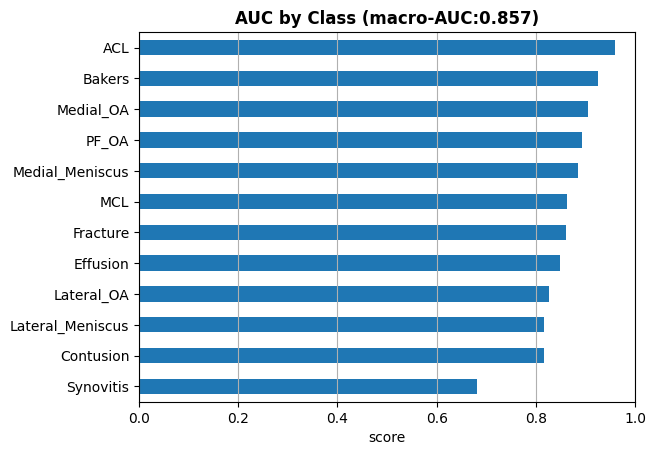

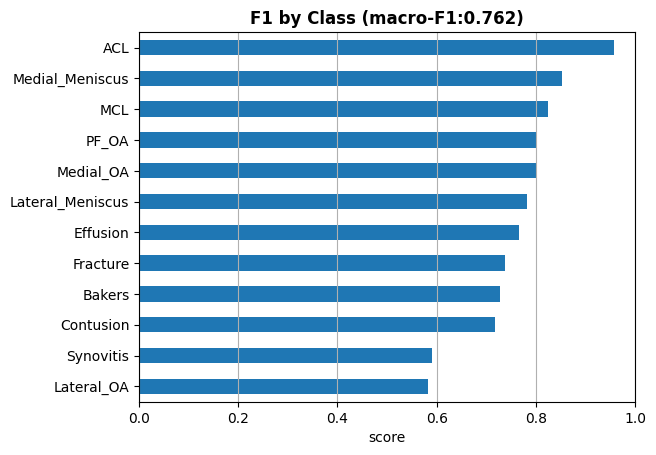

In [2]:
# The provided radiology reports are multilingual, including English, Spanish, Dutch, Greek, Turkish, and other languages.
# Introducing an intermediate translation step adds an additional source of error and may degrade the reliability of the extracted labels.

# Instead, use an instruction-tuned multilingual LLM to directly infer the `TARGETS` from the original reports.
# Calibrate and validate the LLM on the 58 labelled cases before applying it to the larger unlabelled dataset.

# ref:
# ----
# - https://aclanthology.org/anthology-files/anthology-files/pdf/clinicalnlp/2026.clinicalnlp-1.35.pdf
# - https://www.sciencedirect.com/science/article/pii/S0720048X25004279


# Recent studies have demonstrated that few-shot approaches can significantly outperform
# zero-shot approaches in similar domain tasks.

# ref: 
# ----
# - https://arxiv.org/pdf/2511.10658
# - https://pubs.rsna.org/doi/pdf/10.1148/ryai.240551


# CRITICAL:
# *********
# [1.] Although deliberate efforts were made to keep the LLM-extractor grounded in semantic understanding and anatomical definitions rather than keyword lookup, 
# the 58 annotated reference sets were manually reviewed to understand common MRI reporting practices, and a few reports were also used as `few-shot examples`.
# Hence, the influence of the reference set on the prompt cannot be ruled out, 
# and the reported numbers in this section should be interpreted as `eval set performance`. 
# Since no other ground-truth labels are available, we cannot evaluate true `held-out set performance`.
#
# [2.a] We explicitly avoid null-value imputation based on co-occurrence and process each of the 12 labels independently.
# The annotated reference set is <2% of the total training set. Any empirical estimate of the form P(A|B) 
# derived from this reference set may not hold for the full dataset, especially if the reference set was hand-picked to demonstrate all 12 label classes.
# Without sufficient medical-domain knowledge, such co-occurrence patterns may simply reflect spurious correlations.
#
# [2.b] Similarly, any empirical estimate of the form P(abnormality | category of report)
# derived from this small reference set may not generalize to the full dataset.
# Therefore, we only encode the ordinal information of the categories in an uncalibrated score between 0 - 1:
#    NEGATIVE < NA < LOW < MEDIUM < HIGH


from sklearn.metrics import roc_auc_score, f1_score
import matplotlib.pyplot as plt

# TRUE vs PREDICTED LABELS ----
REF = LABELLED[TARGETS].rename(
    columns={
        "ACL":'''ACL''', "MCL":'''MCL''',
        "Medial Meniscus":'''Medial_Meniscus''', "Lateral Meniscus":'''Lateral_Meniscus''',
        "Medial OA":'''Medial_OA''', "Lateral OA":'''Lateral_OA''', "PF OA":'''PF_OA''',
        "Effusion":'''Effusion''', "Synovitis":'''Synovitis''',
        "Baker's":'''Bakers''',
        "Contusion":'''Contusion''', "Fracture":'''Fracture''',
    }
)

PRED= (
    pd.read_csv(
        INPUT/"datasets/ramitnandi/rsna-knee-labels-gpt-luna/report_labels.csv",
        index_col="StudyInstanceUID", usecols=["StudyInstanceUID","CLASS","SCORE","FINAL_LABEL"], 
        dtype={"StudyInstanceUID":'string', "CLASS":'string', "SCORE":float, "FINAL_LABEL":bool},
    )
    .loc[REF.index]
    .pivot(
        columns="CLASS",
        values=["SCORE","FINAL_LABEL"],
    )
)

# ----

# AUC score ----
AUC = pd.Series(
    roc_auc_score(
        REF, PRED["SCORE"].reindex_like(REF),
        average=None,
    ),
    index=REF.columns, name="AUC",
)
AUC.sort_values().plot(
    kind="barh",
    xlabel="score",
    xlim=(0, 1),
)
plt.title(f"AUC by Class (macro-AUC:{AUC.mean():.3f})", fontweight="bold")
plt.grid(axis="x")
plt.show()

# ----

# F1 score ----
F1 = pd.Series(
    f1_score(
        REF, PRED["FINAL_LABEL"].reindex_like(REF).astype(bool),
        average=None,
    ),
    index=REF.columns, name="F1",
)
F1.sort_values().plot(
    kind="barh",
    xlabel="score",
    xlim=(0, 1),
)
plt.title(f"F1 by Class (macro-F1:{F1.mean():.3f})", fontweight="bold")
plt.grid(axis="x")
plt.show()

# ----


# COMMENT: `Synovitis` remains the break-point of this project, and this behaviour is already well-documented in the related literature.
# (see, https://www.sciencedirect.com/science/article/pii/S1063458410002438  https://www.sciencedirect.com/science/article/pii/S266591312500038X )
#
# For classes like Lateral OA, F1 fluctuates on borderline (severity=LOW) cases sensitive to the hard threshold;
# But the high AUC shows the underlying POSITIVE/NEGATIVE ordinal ranking is learned well regardless.

# **[Step-2]** Train a multi-label classifier to predict the TARGETS from the corresponding DICOM images.